In [ ]:
import sys
from os.path import join as pjoin
import os
import platform

mat_version = 1196

platstring = platform.platform()
system = platform.system()
if os.environ.get("SWDB_DATA_ROOT"):
    data_root = os.environ["SWDB_DATA_ROOT"]
elif system == "Darwin":
    data_root = "/Volumes/Brain2026/"
elif system == "Windows":
    data_root = "E:/"
elif "amzn" in platstring:
    data_root = "/data/"
else:
    data_root = "/media/$USERNAME/Brain2026/"

data_dir = pjoin(data_root, "v1dd_1196_ccm")

project_id = "v1dd"
synapse_table_id = "v1dd_1196_synapses"
synapse_feature_matrix_id = "v1dd_1196_synapse_features"
axon_dataset_id = "v1dd_1196_proofread_axons"
dendrite_dataset_id = "v1dd_1196_proofread_dendrites"
cell_type_hierarchy_id = "v1dd_cell_types_r84"
cave_reference_space_id = "v1dd_cave_nm"
streamline_reference_space_id = "v1dd_streamline_nm"

for _candidate in [pjoin("..", "utils"), pjoin("code", "utils"), "utils"]:
    if os.path.isdir(_candidate):
        utils_dir = os.path.abspath(_candidate)
        break
else:
    raise FileNotFoundError(
        "Could not locate the 'utils' directory. Current working directory: "
        f"{os.getcwd()}"
)

sys.path.append(utils_dir)

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<h2> Import packages </h2>
   
</div>

In [ ]:
from connects_common_connectivity.io import (
    DatasetReader,
    read_spatial_locations,
    read_synapse_table,
)
from connects_common_connectivity.models import LocationType

import pandas as pd
import polars as pl
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from scipy.sparse import csr_array
from typing import Union, Optional

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">
   
<b> Common Connectivity dataset setup</b>

<p>Initialize a Common Connectivity <code>DatasetReader</code> for the mounted V1DD dataset.</p>

</div>

In [3]:
# Initialize the Common Connectivity dataset reader
reader = DatasetReader(data_dir)
reader.display_dataset_names() # see available cohorts

id,name,project_id,modality
str,str,str,str
"""v1dd_1196_em""","""V1DD release 1196 — EM somas""","""v1dd""","""ELECTRON_MICROSCOPY"""
"""v1dd_1196_proofread_axons""","""V1DD release 1196 — proofread …","""v1dd""","""ELECTRON_MICROSCOPY"""
"""v1dd_1196_proofread_dendrites""","""V1DD release 1196 — proofread …","""v1dd""","""ELECTRON_MICROSCOPY"""


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

    
## Proofreading and data quality

Understanding this variablity in data quality is critical when interpretting electron microscopy reconstructions.

Automated segmentation of neuronal processes in dense EM imaging is challenging at the size of entire neurons, which can have millimeters of axons and dendrites. The automated segmentation algorithms used in the EM data for this project are not perfect, and so proofreading is necessary to obtain accurate reconstructions of a cell and confidence in the connectivity

In general, the **dendrites** of single-soma detected neurons are considered trustworthy, even without proofreading. However the **axons** require manual effort to both clean and extend. 

For details on the proofreading status see: 

*  `code/data_extraction/DataProducts.ipynb` for how the data we use today was generated
* Proofreading page in the <a href=https://allenswdb.github.io/anatomy/microns-em/proofreading.html> SWDB databook</a>

<b> For this workshop, we treat all cells with at least `axon_partially_extended` as equally trustworth.</b> This may not be a safe assumption for all analysis, and we are happy to provide more guidance depending on the research question.

<font size=3>Load the prepared variables: <code>dendrite_proof_root_ids</code> and <code>axon_proof_root_ids</code> </font>
    
</div>

In [4]:
# Loads cells with axon and dendrite proofreading
proofread_axons = reader.read_dataset(axon_dataset_id)
proofread_dendrites = reader.read_dataset(dendrite_dataset_id)

dendrite_proof_root_ids = proofread_dendrites[
    "dataitem_id"
].cast(pl.UInt64).to_numpy()
axon_proof_root_ids = proofread_axons["dataitem_id"].cast(pl.UInt64).to_numpy()

print(
    f"There are {len(dendrite_proof_root_ids)} cells with acceptable dendrites, and {len(axon_proof_root_ids)} cells with axon proofreading"
)

There are 63986 cells with acceptable dendrites, and 1164 cells with axon proofreading


In [30]:
proofread_axons.head()

dataitem_id,soma_voxel_x,soma_voxel_y,soma_voxel_z,soma_transformed_x,soma_transformed_y,soma_transformed_z,soma_volume,v1dd_cell_types_level_0,v1dd_cell_types_level_1,v1dd_cell_types_level_2
str,f32,f32,f32,f32,f32,f32,f32,str,str,str
"""864691132534275418""",739373.0,633371.0,323640.0,-149.843155,313.619446,40.652767,224.683212,"""neuron""","""E""","""L4-IT"""
"""864691132534315610""",823103.0,635932.0,272970.0,-64.431221,301.977539,-9.080418,236.639908,"""neuron""","""E""","""L4-IT"""
"""864691132535664474""",972173.0,1.006782e6,429480.0,-56.727604,731.348511,-1.565523,300.366089,"""neuron""","""E""","""L6-CT"""
"""864691132536286810""",860041.0,818137.0,270495.0,-68.294258,481.953278,-64.048157,278.909668,"""neuron""","""I""","""DTC"""
"""864691132536904794""",940822.0,738674.0,146565.0,41.834404,367.661865,-158.078094,273.808777,"""neuron""","""I""","""DTC"""


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

    
## Synapse information

While synapses are stored as any other CAVE table in the database, in this case `synapses_v1dd`, this table is much larger than any other table at almost <b>640 million rows</b>, and it works best when queried in a directed way.

For today's workshop we have collected all of the input and output synapses for the proofread cells When accessing CAVE, the `synapse_query()` function allows you to query the synapse table in a more convenient way than most other tables. In particular, the `pre_ids` and `post_ids` let you specify which root id (or collection of root ids) you want to query, with pre_ids indicating the collection of presynaptic neurons and post_ids the collection of postsynaptic neurons.

Note that synapse queries always return the list of every synapse between the neurons in the query, even if there are multiple synapses between the same pair of neurons.

A common pattern to generate a list of connections between unique pairs of neurons is to group by the root ids of the presynaptic and postsynaptic neurons and then count the number of synapses between them. 

<font size=4> Load the table of connections between proofread cells (about <b> 8 million </b> entries) </font>
    
</div>

In [ ]:
synapse_data = read_synapse_table(
    project_id,
    synapse_table_id=synapse_table_id,
    features=True,
    feature_matrix_id=synapse_feature_matrix_id,
    output_root=data_dir,
)

target_structure = (
    synapse_data.select(
        pl.col("id").cast(pl.UInt64), "synaptictargetlabel"
    )
    .to_pandas()
    .set_index("id")["synaptictargetlabel"]
)

syn_df = (
    synapse_data.with_columns(
        pl.col("id").cast(pl.UInt64),
        pl.col("presynaptic_cell").cast(pl.UInt64),
        pl.col("postsynaptic_cell").cast(pl.UInt64),
    )
    .rename(
        {
            "presynaptic_cell": "pre_pt_root_id",
            "postsynaptic_cell": "post_pt_root_id",
        }
    )
    .select(
        [
            "id",
            "pre_pt_position_x",
            "pre_pt_position_y",
            "pre_pt_position_z",
            "post_pt_position_x",
            "post_pt_position_y",
            "post_pt_position_z",
            "ctr_pt_position_x",
            "ctr_pt_position_y",
            "ctr_pt_position_z",
            "size",
            "pre_pt_root_id",
            "post_pt_root_id",
        ]
    )
    .to_pandas()
)

print(syn_df.shape)
syn_df.head(3)

(8204497, 13)


,id,pre_pt_position_x,pre_pt_position_y,pre_pt_position_z,post_pt_position_x,post_pt_position_y,post_pt_position_z,ctr_pt_position_x,ctr_pt_position_y,ctr_pt_position_z,size,pre_pt_root_id,post_pt_root_id
0,354386968,758200.5,802316.1,304380.0,757861.0,802558.6,304650.0,757967.7,802597.4,304380.0,240,864691132536286810,864691132734919083
1,378070488,792063.2,514342.5,183735.0,792664.6,514284.3,183915.0,792412.4,514294.0,183735.0,3056,864691132572190492,864691132606767301
2,499493001,977071.3,390075.8,191340.0,976974.3,390104.9,190935.0,976838.5,390337.7,190935.0,1346,864691132573738810,864691132747578447


In [29]:
synapse_data.head()

project_id,id,presynaptic_cell,postsynaptic_cell,dataset_id,pre_pt_position_x,pre_pt_position_y,pre_pt_position_z,post_pt_position_x,post_pt_position_y,post_pt_position_z,ctr_pt_position_x,ctr_pt_position_y,ctr_pt_position_z,size,synaptictargetlabel
str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,str
"""v1dd""","""354386968""","""864691132536286810""","""864691132734919083""","""v1dd_1196_em""",758200.5,802316.1,304380.0,757861.0,802558.6,304650.0,757967.7,802597.4,304380.0,240,"""shaft"""
"""v1dd""","""378070488""","""864691132572190492""","""864691132606767301""","""v1dd_1196_em""",792063.2,514342.5,183735.0,792664.6,514284.3,183915.0,792412.4,514294.0,183735.0,3056,"""shaft"""
"""v1dd""","""499493001""","""864691132573738810""","""864691132747578447""","""v1dd_1196_em""",977071.3,390075.8,191340.0,976974.3,390104.9,190935.0,976838.5,390337.7,190935.0,1346,null
"""v1dd""","""119675985""","""864691132572564252""","""864691132654028028""","""v1dd_1196_em""",444260.0,602544.6,3285.0,443988.4,602311.8,3555.0,444182.4,602370.0,3780.0,3637,null
"""v1dd""","""220616943""","""864691132558380553""","""864691132828255906""","""v1dd_1196_em""",574501.9,337249.6,258570.0,574152.7,337016.8,258570.0,574337.0,336900.4,258570.0,420,null


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

    

<ul>This table has a number of columns, we will highlight the most important
    <li><b> id:</b> a unique ID for each synapse </li>
    <li><b> pre_pt_root_id:</b> the segmentation ID of the pre-synaptic compartment</li>
    <li><b> post_pt_root_id:</b> the segmentation ID of the post-synaptic compartment</li>
    <li><b> size:</b> a measure of the synapse size (the number of 4,4,40 nm voxels in the synapse mask) best available metric of synaptic weight</li>
    <li><b> ctr_pt_position_{x,y,z}:</b> the location of the synapse in the cleft, stored here in nanometers</li>
    <li><b> pre_pt_position_{x,y,z}:</b> a point just in the presynaptic compartment of synapse (used to lookup pre_root_id), stored here in nanometers</li>
    <li><b> post_pt_position_{x,y,z}:</b> a point just in the postsynaptic compartment of synapse (used to lookup post_pt_root_id), stored here in nanomaters</li>
</ul>

</div>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

    
## Combining neuron morphology & synapses

<p> Next we will visualize the synapses on the skeleton of your cell of interest. </p>

<p> Here we define a convenience function for robustly filtering the synapse table by pre- or post-synaptic partners. You will use this through the rest of the exercises. </p> 
    
</div>

In [6]:
def filter_synapse_table(
    synapse_table: pd.DataFrame, pre_root_ids=None, post_root_ids=None
):
    """Filter synapse table by pre and post root ids.

    Args:
        synapse_table: synapse table with pre_pt_root_ids and post_pt_root_ids as pd.DataFrame
        pre_root_ids: np.ndarray, list or pd.Series if root_ids to filter on the presynaptic side
        post_root_ids: np.ndarray, list or pd.Series if root_ids to filter on the postsynaptic side

    Returns:
        synapse_table: filtered synapse table
    """

    if pre_root_ids is not None:
        assert isinstance(pre_root_ids, (np.ndarray, list, pd.core.series.Series)), (
            f"IDs have to be of type np.ndarray, list or pd.Series; got {type(pre_root_ids)}"
        )
        pre_mask = np.isin(synapse_table["pre_pt_root_id"], pre_root_ids)
    else:
        pre_mask = np.ones(len(synapse_table), dtype=bool)

    if post_root_ids is not None:
        assert isinstance(post_root_ids, (np.ndarray, list, pd.core.series.Series)), (
            f"IDs have to be of type np.ndarray, list or pd.Series; got {type(pre_root_ids)}"
        )
        post_mask = np.isin(synapse_table["post_pt_root_id"], post_root_ids)
    else:
        post_mask = np.ones(len(synapse_table), dtype=bool)

    return synapse_table[pre_mask & post_mask]


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

    
<h3> Collect the output synapses for your cell of interest. </h3>

The nomenclature here is that you want synapses where your cell is the **presynaptic** partner

</div>

In [7]:
# select from the cells which are fully extended
root_id = axon_proof_root_ids[1]  # iterate this number to choose a different cell

# Query the skeleton from CAVEclient
# sk_d = client.skeleton.get_skeleton(root_id, output_format="dict")

pre_syns = filter_synapse_table(syn_df, pre_root_ids=[root_id])

pre_syns.head(5)

,id,pre_pt_position_x,pre_pt_position_y,pre_pt_position_z,post_pt_position_x,post_pt_position_y,post_pt_position_z,ctr_pt_position_x,ctr_pt_position_y,ctr_pt_position_z,size,pre_pt_root_id,post_pt_root_id
133,402558233,839602.9,564646.7,228735.0,839515.6,565160.8,229410.0,839699.9,565034.7,229095.0,3881,864691132534315610,864691132726874269
207,292446107,675478.9,569525.8,361440.0,675333.4,569700.4,361125.0,675469.2,569603.4,361305.0,1082,864691132534315610,864691132620269499
383,438169048,865899.6,475571.6,202005.0,865725.0,476095.4,202230.0,865695.9,475872.3,202005.0,5146,864691132534315610,864691132569299996
399,409065816,843327.7,769995.7,336240.0,843395.6,770277.0,336420.0,843405.3,770315.8,336285.0,1694,864691132534315610,864691133066825032
473,397169708,811715.4,751885.8,267750.0,811715.4,751730.6,267525.0,811763.9,751720.9,267750.0,1664,864691132534315610,864691132959793255


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

## Synapse matrix

The synapses between neurons create a network of synaptic connections. One way of visualizing this connectivity is in matrix form. 

For now, we will limit ourselves to the synapses between the proofread neurons.

</d>

In [8]:
# get the ids of all proofread cells with both axon and dendrite proofreading
proof_root_ids = axon_proof_root_ids[
    np.isin(axon_proof_root_ids, dendrite_proof_root_ids)
]

# filter for synapses between the proofread cells (pre and post)
proof_proof_syn_table = filter_synapse_table(
    syn_df, pre_root_ids=proof_root_ids, post_root_ids=proof_root_ids
)

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

Next we will make an **adjacency plot** from the tabular synapse data, turning it into a matrix the describes the connection strength between all possible partners. For convenience we have provided a function `make_adjacency` to perform the ordered groupbys and aggregations. 

</d>

In [9]:
from utils import check_index


def make_adjacency(
    synapses,
    source_cell_index: Union[pd.Index, pd.DataFrame, pd.Series, np.ndarray, list],
    target_cell_index: Optional[
        Union[pd.Index, pd.DataFrame, pd.Series, np.ndarray, list]
    ] = None,
    aggfunc="binary",
    return_as="dense",
) -> Union[csr_array, np.ndarray]:
    source_cell_index = check_index(source_cell_index)
    if target_cell_index is None:
        target_cell_index = source_cell_index
    else:
        target_cell_index = check_index(target_cell_index)
    synapses = synapses.query(
        "pre_pt_root_id in @source_cell_index and post_pt_root_id in @target_cell_index"
    )
    groupby = synapses.groupby(["pre_pt_root_id", "post_pt_root_id"])
    if aggfunc == "count":
        edges = groupby.size().rename("weight").reset_index()
    elif aggfunc == "binary":
        edges = groupby.size().transform(lambda x: x > 0).rename("weight").reset_index()
    else:
        edges = groupby["size"].agg(aggfunc).rename("weight").reset_index()
    # make sure that the adjacency matrix is sorted the same as the input cell index
    edges["source_index"] = source_cell_index.get_indexer(edges["pre_pt_root_id"])
    edges["target_index"] = target_cell_index.get_indexer(edges["post_pt_root_id"])
    adjacency = csr_array(
        (edges["weight"], (edges["source_index"], edges["target_index"])),
        shape=(len(source_cell_index), len(target_cell_index)),
        dtype=edges["weight"].dtype,
    )
    # NOTE: for many applications working with sparse matrices is more efficient
    # but for ease of use and visualization in this workshop we return a dense matrix
    if return_as == "dense":
        adjacency = adjacency.todense()
    elif return_as == "sparse":
        pass  # already in sparse format
    else:
        raise ValueError(f"Unknown return_as type: {return_as}")
    return adjacency


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

Each synapse has a `size` value assigned to it. How to aggregate the sizes from multiple synapes between two neurons depends on the research question. Synapse sizes vary by a lot and are related to the physiological strength of a synapse ([Holler et al., 2021](https://www.nature.com/articles/s41586-020-03134-2)). 

<font size=4> First, we will ignore the synapse size and strength and only look at <b>binary (connected yes/no) connectivity</b>. There are other measures of connectivity you can explore below that changes how the network appears. </font3>

</d>

In [10]:
syn_mat = make_adjacency(proof_proof_syn_table, proof_root_ids, aggfunc="binary")
syn_mat

array([[False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       ...,
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False, False, False],
       [False, False, False, ..., False,  True, False]],
      shape=(1148, 1148))

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

It looks like many of the values in the adjacency matrix array are `False`. In other words, most of the neurons in the proofread dataset are not connected to each other. How can we look at the places where there are connections? We can use the `np.nonzero()` function to get the indices of the non-zero (`True`) values in the array.  

</div>

In [11]:
# show the first 10 nonzero values in the array
row_indices, column_indices = np.nonzero(syn_mat)
print("Row indices:", row_indices[:10])
print("Column indices:", column_indices[:10])
print("Matrix values:", syn_mat[row_indices[:10], column_indices[:10]])

Row indices: [0 0 0 0 0 0 0 0 0 0]
Column indices: [118 234 251 262 269 275 393 423 465 579]
Matrix values: [ True  True  True  True  True  True  True  True  True  True]


<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">

<b> Discussion </b>: what does it mean that all of the first 10 values we looked at share the same row index?

</div>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

Now, let's move on to plotting the entire matrix.

</div>

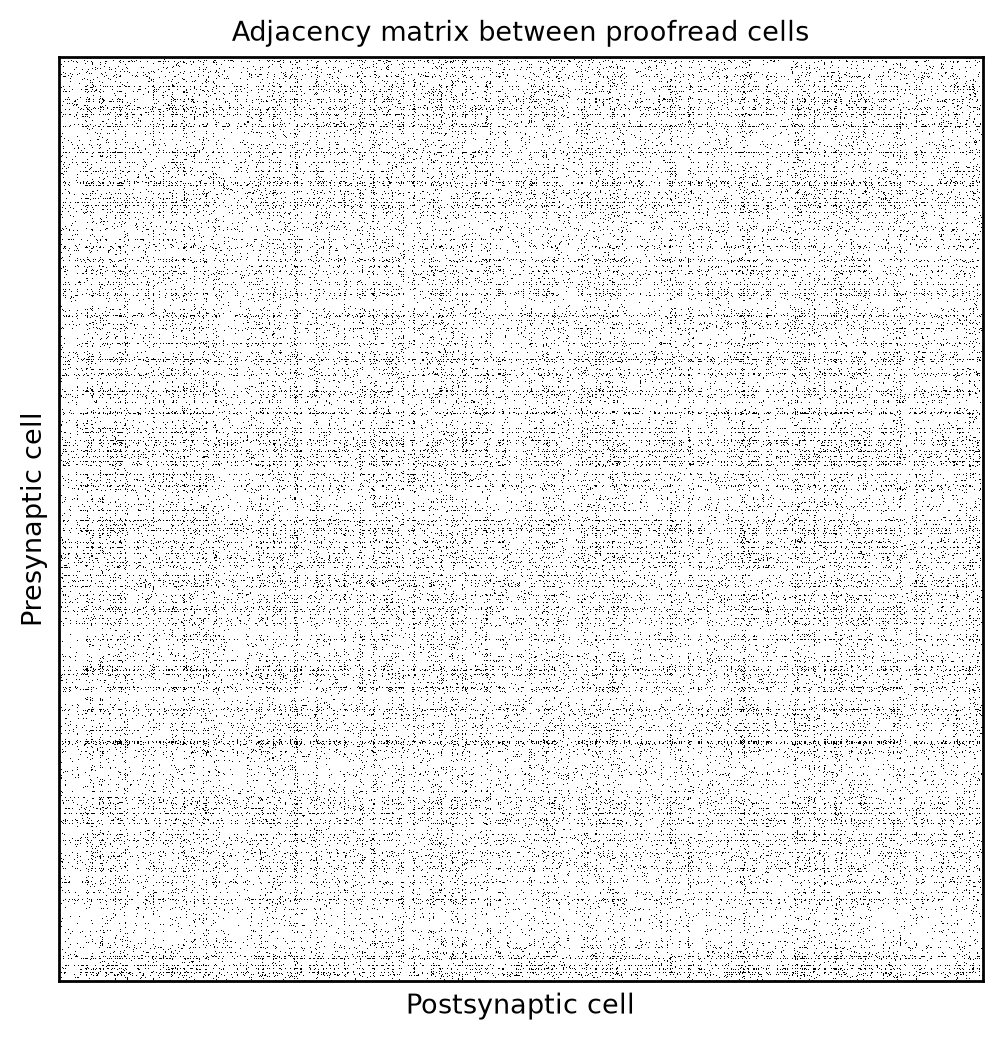

In [12]:
sns.set_context("paper", font_scale=1.0)


fig, ax = plt.subplots(figsize=(6, 6), dpi=200)

sns.heatmap(
    syn_mat,
    cbar=False,
    cmap="Greys",
    xticklabels=False,
    yticklabels=False,
    square=True,
    ax=ax,
)
ax.spines[["left", "right", "top", "bottom"]].set_visible(True)
_ = ax.set(
    xlabel="Postsynaptic cell",
    ylabel="Presynaptic cell",
    title="Adjacency matrix between proofread cells",
)

In [13]:
n_edges = len(row_indices)
n_possible_edges = syn_mat.shape[0] * syn_mat.shape[1]
print(f"Number of edges: {n_edges}")
print(f"Number of possible edges: {n_possible_edges}")
print(f"Fraction of possible edges: {n_edges / n_possible_edges:.4f}")

Number of edges: 90845
Number of possible edges: 1317904
Fraction of possible edges: 0.0689


<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">
<p><b>Task 3:</b> The matrix above only contains connections between <b>axon-proofread neurons</b>. Because many more dendrites of cells in the V1DD dataset are well-reconstructed <b>we can consider more connections than just the ones between proofread neurons.</b> Therefore, the connectivity matrix of analyzable connections forms a rectangular matrix. 
    
What is the size of the matrix between the proofread neurons and all neurons with a cell body in the dataset?
    
</div>

In [14]:
# Select synapses from proofread cells onto all cells
proof_all_syn_table = filter_synapse_table(
    syn_df, pre_root_ids=axon_proof_root_ids, post_root_ids=dendrite_proof_root_ids
)

print(len(proof_all_syn_table))

# make adjanceny matrix from proofread cells onto all cells
rect_syn_mat = make_adjacency(
    syn_df,
    source_cell_index=axon_proof_root_ids,
    target_cell_index=dendrite_proof_root_ids,
)

# print shape of the matrix
rect_syn_mat.shape

1431746


(1164, 63986)

In [15]:
# Select synapses from proofread cells onto all cells
proof_all_syn_table = filter_synapse_table(
    syn_df, pre_root_ids=axon_proof_root_ids, post_root_ids=dendrite_proof_root_ids
)

print(len(proof_all_syn_table))

# make adjanceny matrix from proofread cells onto all cells
rect_syn_mat = make_adjacency(
    syn_df,
    source_cell_index=axon_proof_root_ids,
    target_cell_index=dendrite_proof_root_ids,
)

# print shape of the matrix
rect_syn_mat.shape

1431746


(1164, 63986)

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

<h4> Consider: different measures of synaptic strength </h4>

When creating a connectivity matrix, how you measure synaptic strength can make a difference in your analysis. For EM data there are 3 common ways of reporting connection strength:

<ol>
    <li> <b> Binary connectivity:</b> whether two cells are connected at all, as shown above.</li>
    <li> <b> Synaptic count:</b> the total number of synapses that are part of the connection. This is typical of the Fly connectome where <code>count</code> captures much of the connection diversity. The modal <code>count</code> in mouse cortex is much lower.</li>
    <li> <b> Synaptic size:</b> the size of the postsynaptic density at every connection, generally aggregated as <code>sum</code> or <code>mean</code> for each unique connection.</li>
    
</ol>
How to take synapse size and number into account depends on the specific analysis. 

The `size` reported in the V1DD dataset measures the synaptic cleft as segmented by the automated classifier in voxels (3d pixels, a measure of volume). These are correlated to anatomical measures such as synaptic area and spine head volumes (for excitatory synapses). 

Let's replot the <b>square matrix</b> with the <code>sum</code> of synapses sizes between each connected pair.

</d>

In [16]:
# get the ids of all proofread cells (same as for the binary connectivity)
proof_root_ids = axon_proof_root_ids[
    np.isin(axon_proof_root_ids, dendrite_proof_root_ids)
]

# Now with the aggregation function set to 'mean' synapse size
syn_mat = make_adjacency(syn_df, source_cell_index=proof_root_ids, aggfunc="sum")

# show the first 10 nonzero values in the array
row_indices, column_indices = np.nonzero(syn_mat)
print("Row indices:", row_indices[:10])
print("Column indices:", column_indices[:10])
print("Matrix values:", syn_mat[row_indices[:10], column_indices[:10]])

Row indices: [0 0 0 0 0 0 0 0 0 0]
Column indices: [118 234 251 262 269 275 393 423 465 579]
Matrix values: [2620  898 3828 4488 1556 4965 1436  631  270 3425]


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

The matrix values are now **sum of size** rather than the True/False. It is useful to understand the full range of synaptic strength represented, plotted below first on a linear axis then a log axis

</d>

[Text(0.5, 0, 'Sum synapse size (voxels - log scale)'),
 Text(0, 0.5, 'Number of connections')]

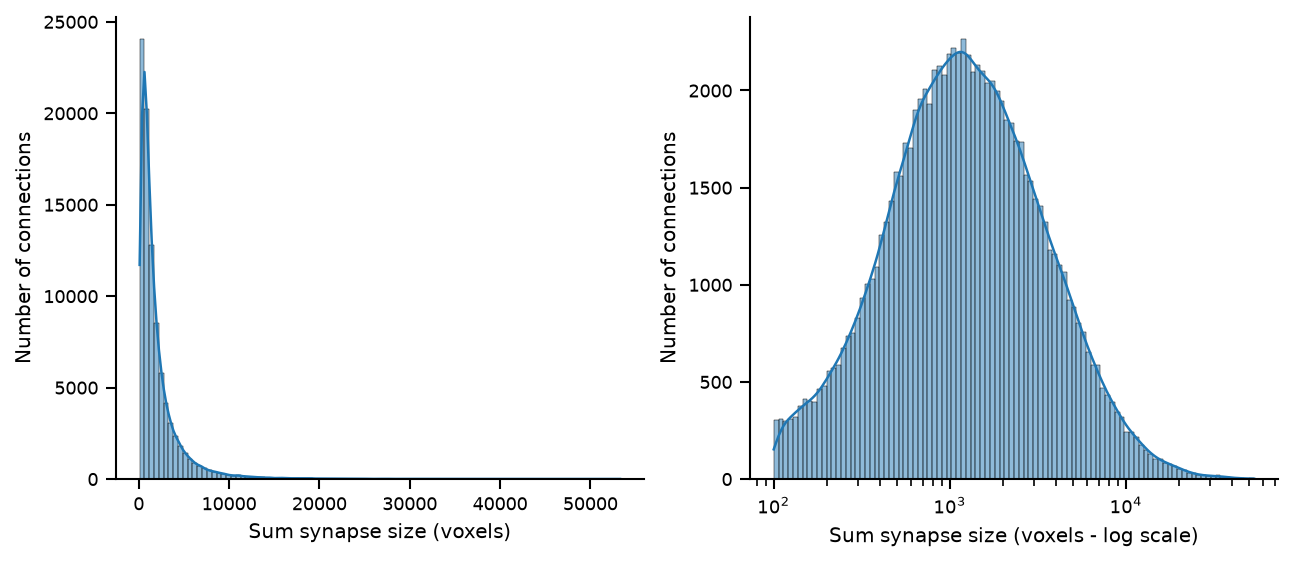

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), dpi=150)

# collect the synaptic weights that are non-zero
edge_weights = syn_mat[row_indices, column_indices]

# Histogram on linear-x
ax = axs[0]
sns.histplot(
    edge_weights,
    kde=True,
    bins=100,
    ax=ax,
)
ax.spines[["top", "right"]].set_visible(False)
ax.set(xlabel="Sum synapse size (voxels)", ylabel="Number of connections")

# Histogram on log-x
ax = axs[1]
sns.histplot(
    edge_weights,
    kde=True,
    bins=100,
    ax=ax,
    log_scale=True
)
ax.spines[["top", "right"]].set_visible(False)
ax.set(xlabel="Sum synapse size (voxels - log scale)", ylabel="Number of connections")

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

Replot the square matrix with `sum` of synapse size. 

</d>

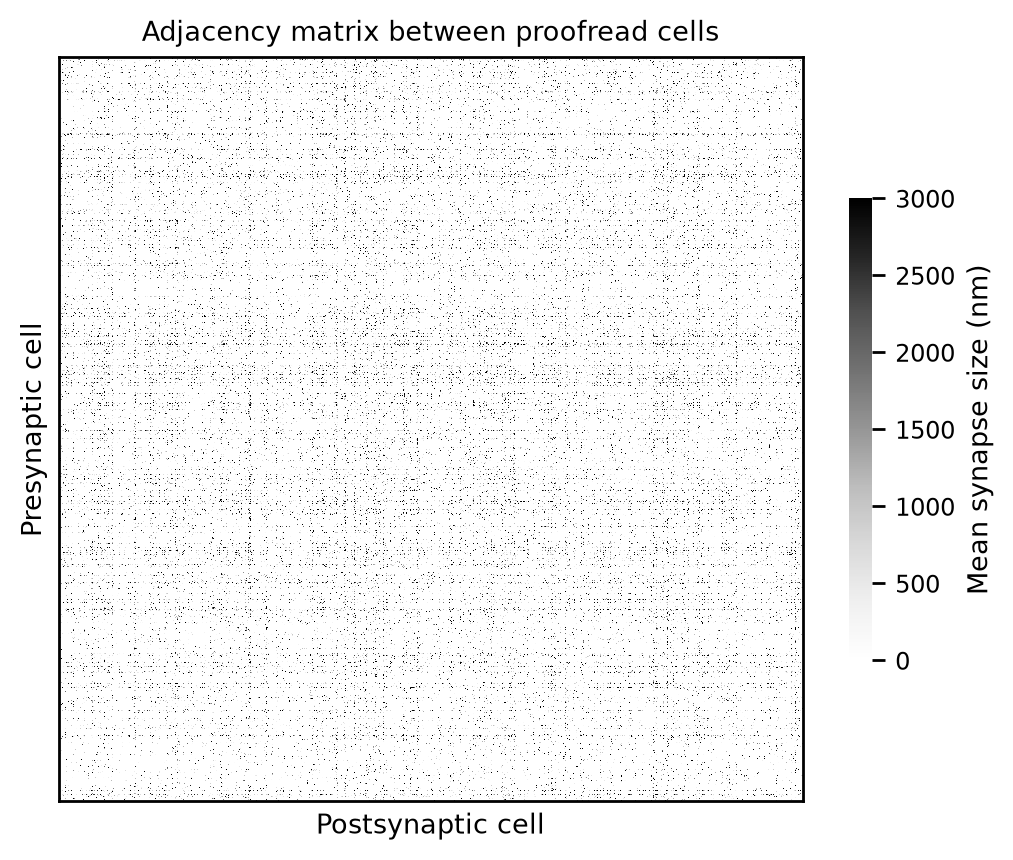

In [18]:
fig, ax = plt.subplots(figsize=(6, 6), dpi=200)
sns.heatmap(
    syn_mat,
    cbar=True,
    cmap="Greys",
    xticklabels=False,
    yticklabels=False,
    square=True,
    vmax=3000,  # set the upper bound on color scale so that we can see more edges
    ax=ax,
    cbar_kws={"label": "Mean synapse size (nm)", "shrink": 0.5},
)
ax.spines[["left", "right", "top", "bottom"]].set_visible(True)
_ = ax.set(
    xlabel="Postsynaptic cell",
    ylabel="Presynaptic cell",
    title="Adjacency matrix between proofread cells",
)

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

Depending on the connection type, number of synapses might be the more important measure (see [Dorkenwald et al., 2022](https://elifesciences.org/articles/76120) for deeper dive into synapse size and counts). 

</d>

[Text(0.5, 0, 'Number of synapses per connection'),
 Text(0, 0.5, 'Number of connections')]

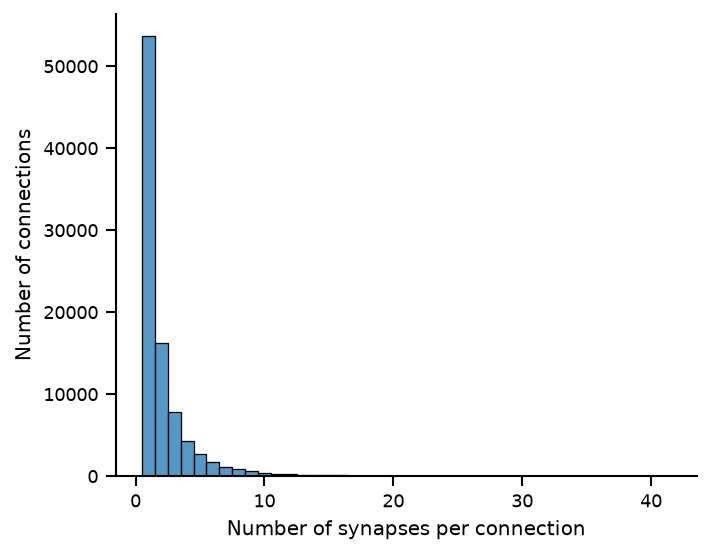

In [19]:
# generate adjacenty matrix with a count of synapses
syn_mat = make_adjacency(syn_df, proof_root_ids, aggfunc=lambda x: np.sum(x > 0))

# Histogram on linear-x
fig, ax = plt.subplots(figsize=(5, 4), dpi=150)
edge_weights = syn_mat[row_indices, column_indices]
sns.histplot(
    edge_weights,
    discrete=True,
    ax=ax,
)
ax.spines[["top", "right"]].set_visible(False)
ax.set(xlabel="Number of synapses per connection", ylabel="Number of connections")

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

Next we plot the <b>number of synapses per connection</b> or the <code>count</code>(we limit the colorbar to a maximum of 5 but the actual max number is much higher):

</div>

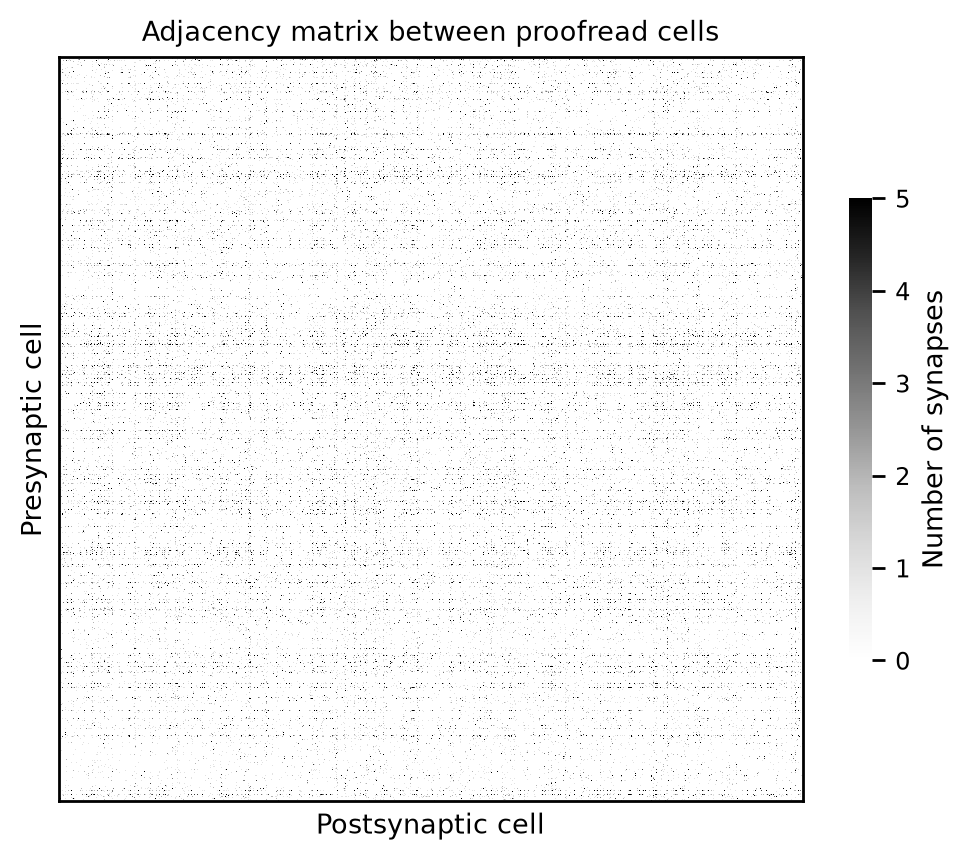

In [20]:
fig, ax = plt.subplots(figsize=(6, 6), dpi=200)
sns.heatmap(
    syn_mat,
    cbar=True,
    cmap="Greys",
    xticklabels=False,
    yticklabels=False,
    square=True,
    vmax=5,  # clip the color scale to 5 to see more edges
    ax=ax,
    cbar_kws={"label": "Number of synapses", "shrink": 0.5},
)
ax.spines[["left", "right", "top", "bottom"]].set_visible(True)
_ = ax.set(
    xlabel="Postsynaptic cell",
    ylabel="Presynaptic cell",
    title="Adjacency matrix between proofread cells",
)

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

## Cell type tables

Identifying the putative ‘cell type’ from the EM morphology is a process that involves both manual and automatic classifications. Subsets of the dataset have been manually classified by anatomists at the Allen Institute, and these ground truth labels used to train and refine different automated ‘feature classifiers’ over time. 

Two of the most predictive features for broad cell type are:

<ul>
    <li>Soma location (in units of depth from pial surface). This captures <b>cortical layer diversity</b></li>
    <li>Soma size (in units of volume). This is a strong proxy of many types of <b>cell morpholigical diversity</b></li>
</ul>

<font size=4>Load the cell types data and plot all the cells by these two features</font>
    
</d>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

### Using the automated cell types

Many of these automated cell type definitions were established and refined for the [MICrONS Dataset](https://www.microns-explorer.org/) including: 

<ul>
    <li> Perisomatic cell features <a href=https://www.nature.com/articles/s41586-024-07765-7>(Elabbady et al.)</a> </li>
    <li> Morphology and connectivity features <a href=https://www.nature.com/articles/s41586-024-07780-8>(Schneider-Mizell et al.)</a> </li>
</ul>

The process of applying these labels to the V1DD dataset is ongoing, but we will use cell typing from the <code>cell_type_multifeature_v1</code> table which labels cell types according to using soma, nucleus, dendrite, and spine features. 

Excitatory neurons are labeled by projection category (IT, ET, NP, CT, and SP for subplate). 

Inhibitory neurons follow labels based on targeting such as ITC (inhibitory targeting), STC (sparsely targeting), PTC (perisomatic targeting), and DTC (dendrite targeting), but might align more with molecular class than exact targeting for a given neuron, particularly among ITC/VIP cells.

*Note:* Cells here without a label will remain black. These are either non-neuronal cells or potential neurons with large segmentation errors that did not pass quality check
    
</d>

In [ ]:
proofread_dendrite_ids = proofread_dendrites["dataitem_id"].to_list()

cave_locations = read_spatial_locations(
    project_id,
    reference_spaces=cave_reference_space_id,
    dataitem_ids=proofread_dendrite_ids,
    location_types=LocationType.SOMA,
    output_root=data_dir,
).select(
    "dataitem_id",
    pl.col("x").alias("pt_position_x"),
    pl.col("y").alias("pt_position_y"),
    pl.col("z").alias("pt_position_z"),
)

streamline_locations = read_spatial_locations(
    project_id,
    reference_spaces=streamline_reference_space_id,
    dataitem_ids=proofread_dendrite_ids,
    location_types=LocationType.SOMA,
    output_root=data_dir,
).select(
    "dataitem_id",
    pl.col("x").alias("pt_position_trform_x"),
    pl.col("y").alias("pt_position_trform_y"),
    pl.col("z").alias("pt_position_trform_z"),
)

cell_df = (
    proofread_dendrites
    .select(
        "dataitem_id",
        pl.col("soma_volume").alias("volume"),
        pl.col(f"{cell_type_hierarchy_id}_level_1").alias("cell_type_coarse"),
        pl.col(f"{cell_type_hierarchy_id}_level_2").alias("cell_type"),
    )
    .join(cave_locations, on="dataitem_id", how="left")
    .join(streamline_locations, on="dataitem_id", how="left")
    .select(
        pl.col("dataitem_id").cast(pl.UInt64).alias("pt_root_id"),
        "pt_position_x",
        "pt_position_y",
        "pt_position_z",
        "pt_position_trform_x",
        "pt_position_trform_y",
        "pt_position_trform_z",
        "volume",
        "cell_type_coarse",
        "cell_type",
    )
    .to_pandas()
)

cell_df.head()

,pt_root_id,pt_position_x,pt_position_y,pt_position_z,pt_position_trform_x,pt_position_trform_y,pt_position_trform_z,volume,cell_type_coarse,cell_type
0,864691132496108732,1655130.0,605358.0,776205.0,747210.937500,405236.90625,483669.812500,153.827026,None,None
1,864691132511800666,1227399.0,659134.0,270000.0,337011.062500,321753.62500,-17433.791016,257.700134,None,None
2,864691132525163794,1546956.0,533345.0,771210.0,654334.875000,333298.25000,499503.218750,258.204437,None,None
3,864691132533275738,641054.0,609626.0,372420.0,-246859.484375,304183.06250,93715.273438,226.991959,E,L4-IT
4,864691132533347418,805488.0,633759.0,299205.0,-82770.437500,307048.93750,16897.523438,217.654556,E,L4-IT


In [22]:
# Add a column that is soma depth in consistent units
cell_df['depth_um'] = cell_df['pt_position_trform_y'] / 1_000 # from nm to um


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

## Sorting the synapse matrix with cell types
    
Let's combine the synaptic connecitivity with the cell type information. Below we provide logic for sorting a connectivity matrix using a list of labels.    
    
</d>

In [23]:
# Filter the proofread ids for those with a known cell type
proof_root_ids = np.intersect1d(proof_root_ids, cell_df["pt_root_id"].values)

# Filter the cell type table for those with a proofread root id
proof_cell_df = cell_df.set_index("pt_root_id").loc[proof_root_ids]
proof_cell_df = proof_cell_df.query("cell_type.notna()")

# NOTE: the adjacency matrix will be sorted according to this dataframe's index, so
# we'll sort it by soma depth
proof_cell_df = proof_cell_df.sort_values("pt_position_trform_y")

# Make adjacency, now including soma depth and cell type
syn_mat = make_adjacency(syn_df, proof_cell_df, aggfunc="sum")
syn_mat

array([[  0,   0, 274, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       ...,
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0],
       [  0,   0,   0, ...,   0,   0,   0]], shape=(1124, 1124))

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

NOTE: there are slightly fewer cells in this adjacency matrix, because we are filtering for cells that have complete information in the cell table above.

</div>

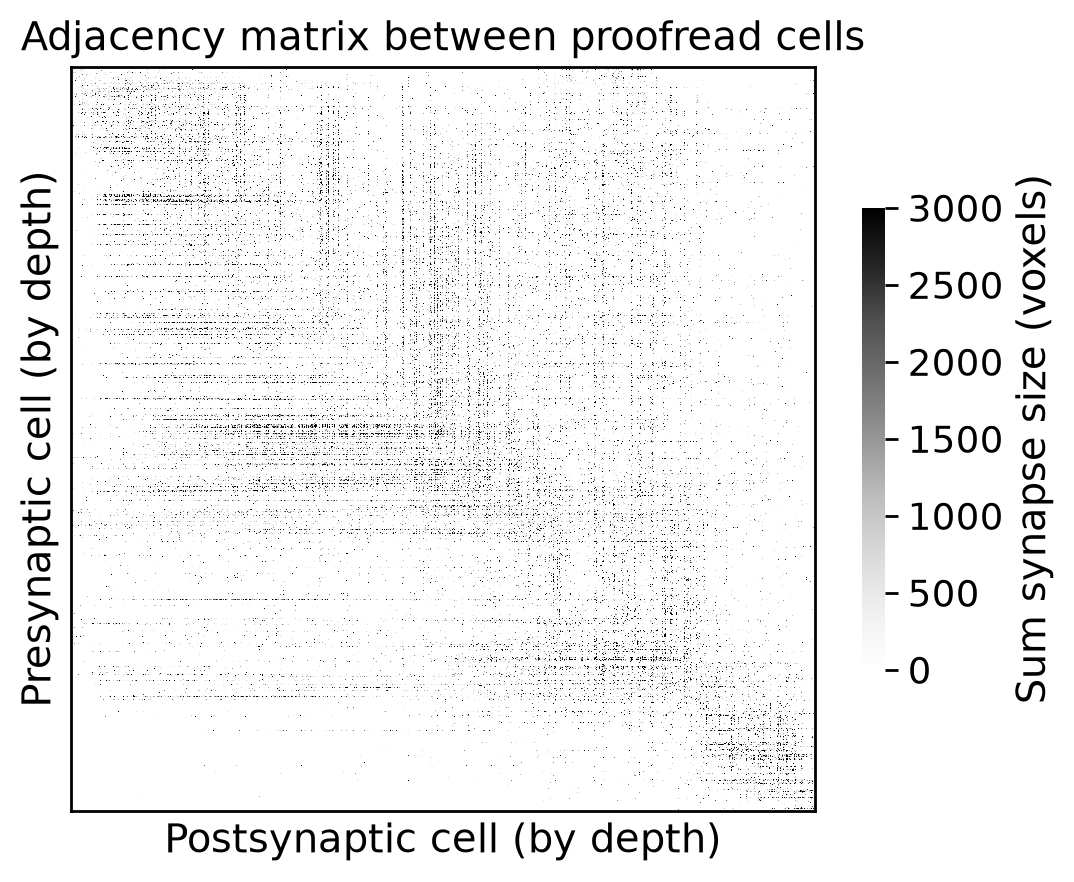

In [24]:
sns.set_context("paper", font_scale=1.5)
fig, ax = plt.subplots(figsize=(6, 6), dpi=200)
sns.heatmap(
    syn_mat,
    cbar=True,
    cmap="Greys",
    xticklabels=False,
    yticklabels=False,
    square=True,
    vmax=3000,
    ax=ax,
    cbar_kws={"label": r"Sum synapse size (voxels)", "shrink": 0.5},
)
ax.spines[["left", "right", "top", "bottom"]].set_visible(True)
_ = ax.set(
    xlabel="Postsynaptic cell (by depth)",
    ylabel="Presynaptic cell (by depth)",
    title="Adjacency matrix between proofread cells",
)

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">
<p><b>Task 4:</b> There is a large amount of structure in the connectivity, just based on soma depth! However, some rows are very narrow in their connectivty while others are very wide.
    
<p><b>Discussion:</b> What are some explanations for why the connectivity plot has a strong diagonal component? In contrast, what does the wide connectivity in a row/column mean </p>
    
</div>

<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

### Add cell type logic to adjacency plot

What about the effect of cell types on the connectivity matrix? We can add colors and subplots by cell type to make this matrix more tractable. We have packaged away the logic for this in `adjacencyplot` which can group and sort the adjacency matrix by metadata in the cell table.

The logic here is similar to the plotting package `seaborn`, where different labels within the data can be leveraged to control different elements.
    
</d>

(<Axes: >, <utils.AxisGrid at 0x7fd441cdb2c0>)

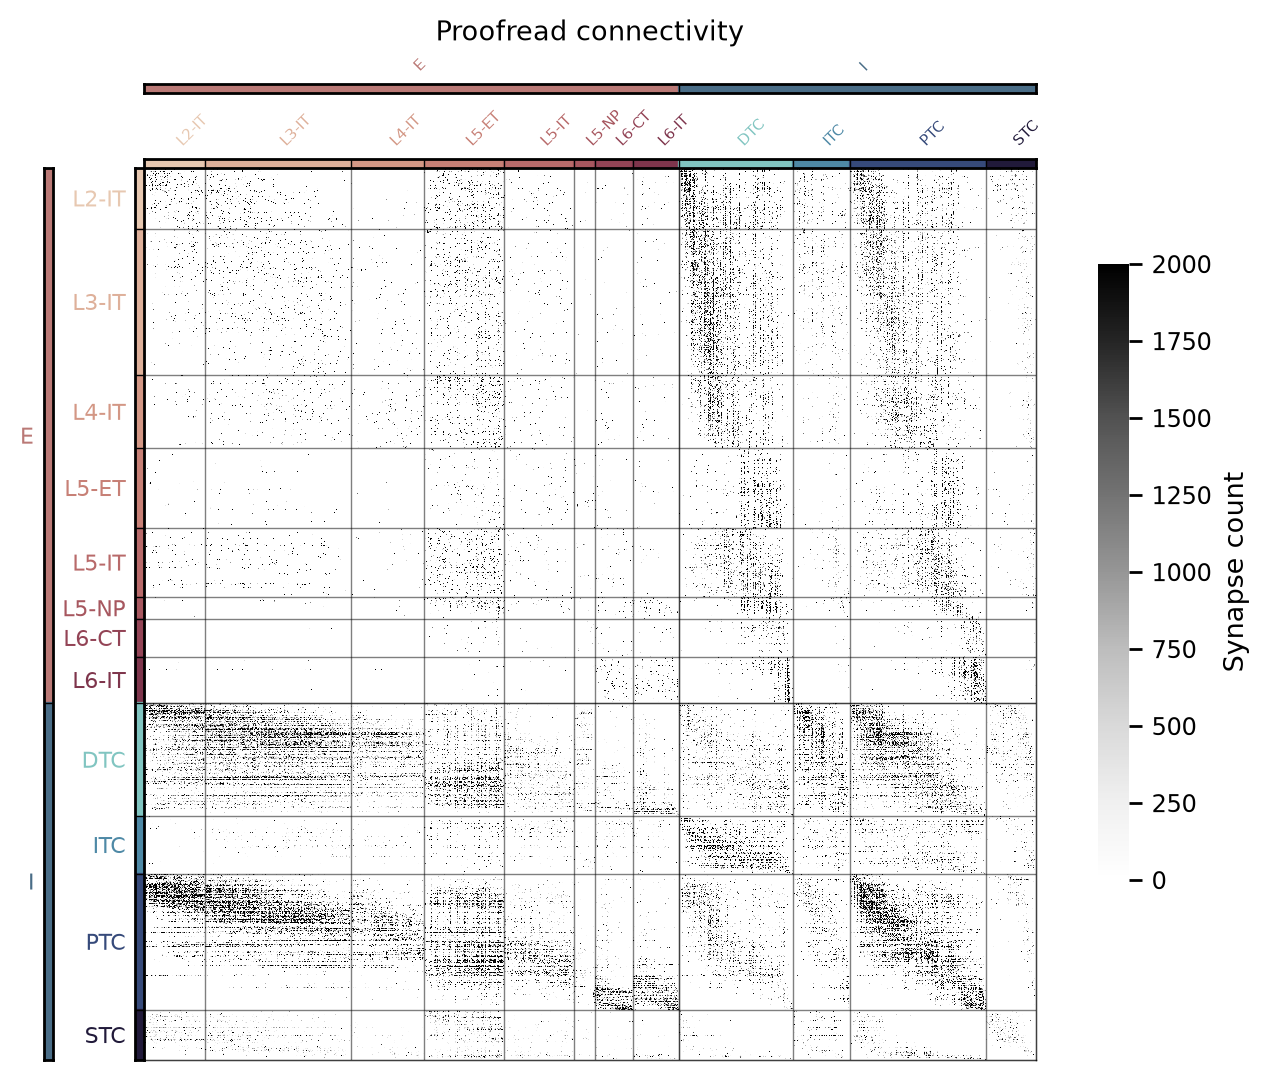

In [25]:
from utils import adjacencyplot, cell_type_palette

sns.set_context('paper', font_scale=1.0)

fig, ax = plt.subplots(figsize=(8, 8), dpi=200)

# render the adjacency plot
adjacencyplot(
    syn_mat,  # data values for the points
    nodes=proof_cell_df,  # data to organize the x and y axis
    groupby=["cell_type_coarse", "cell_type"],  # categorical variables to organize by
    sortby="pt_position_y",  # sort within groups by variable
    node_palette=cell_type_palette,
    title="Proofread connectivity",
    edge_palette="Greys",
    hue_norm=(0, 2000),  # normalize the color scale for the edges
    ax=ax,
    label_fontsize="xx-small",
    title_fontsize="medium",
    arc_labels=False
)

<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">
<p><b>Task 5:</b> Now we have restructured the connectivity based on cell type. Find one of your example cells from earlier and identify it's row or column. Hint: query the <code>proof_cell_df</code> by your <code>root_id</code>

<b>Discussion:</b> Describe the connectivity for your cell by who it targets and who it recieves inputs from.

Then, for each row describe that cell type by it's major targets. Do you think there are more subgroups within the cell types?
    
</div>

In [26]:
# Query the cell type of your root_id:
proof_cell_df.query(f"pt_root_id=={root_id}")[["cell_type_coarse", "cell_type"]]

,cell_type_coarse,cell_type
pt_root_id,,
864691132534315610,E,L4-IT


<div style="border-left: 3px solid #000; padding: 1px; padding-left: 10px; background: #F0FAFF; ">

## Connection specificity onto compartment types
Up until now we have considered all synapses between any two cells, but different synapses target different compartments on the post synaptic cell. 

![](../../figures/sss-diagram.png)

For example, it is common understanding that:

<ol>
    <li> Synapses between excitatory->excitatory cells are onto spines</li>
    <li> Synapses between inhibitory->excitatory cells are onto dendritic shaft</li>
    <li> Synapses onto inhibitory cells are onto dendritic shaft</li>
    <li> Basket cells target soma synapses </li>
</ol>


Let's test this textbook understanding in the real data. 

<font size=4> For this you will need to load in data about the target compartment of the synapse, one of: spine, shaft, soma </font>
    
</d>

In [27]:
# Load the target structure included with the CCM synapse features
target_structure

# Select the synapses between proofread cells
proof_proof_syn_table = filter_synapse_table(
    syn_df, pre_root_ids=proof_root_ids, post_root_ids=proof_root_ids
).copy().set_index('id')

# Combine the target information to the proofread synapses table
proof_proof_syn_table["target_structure"] = target_structure
proof_proof_syn_table["target_structure"] = proof_proof_syn_table[
    "target_structure"
].fillna("unknown")

print(proof_proof_syn_table["target_structure"].value_counts())
proof_proof_syn_table.head()

target_structure
shaft      134631
spine       45679
soma        13248
unknown      1746
Name: count, dtype: int64


,pre_pt_position_x,pre_pt_position_y,pre_pt_position_z,post_pt_position_x,post_pt_position_y,post_pt_position_z,ctr_pt_position_x,ctr_pt_position_y,ctr_pt_position_z,size,pre_pt_root_id,post_pt_root_id,target_structure
id,,,,,,,,,,,,,
461895313,917998.3,772740.8,284220.0,918376.6,772818.4,283815.0,918202.0,773080.3,284085.0,540,864691132557909513,864691132931817448,shaft
301049004,679950.6,813121.9,283050.0,679552.9,812753.3,283095.0,679601.4,812782.4,283140.0,958,864691132578625044,864691132931817448,shaft
436596114,879663.9,750576.3,347715.0,879266.2,750653.9,348120.0,879469.9,750634.5,347940.0,266,864691132557909513,864691132931817448,shaft
363374679,781538.7,726132.3,241110.0,781257.4,726268.1,240480.0,781305.9,725986.8,240705.0,396,864691132578625044,864691132786109590,shaft
491726200,962385.5,676759.3,316035.0,962210.9,677069.7,316620.0,962366.1,676856.3,316305.0,442,864691132562471396,864691132773784759,shaft


(<Axes: >, <utils.AxisGrid at 0x7fd439d05970>)

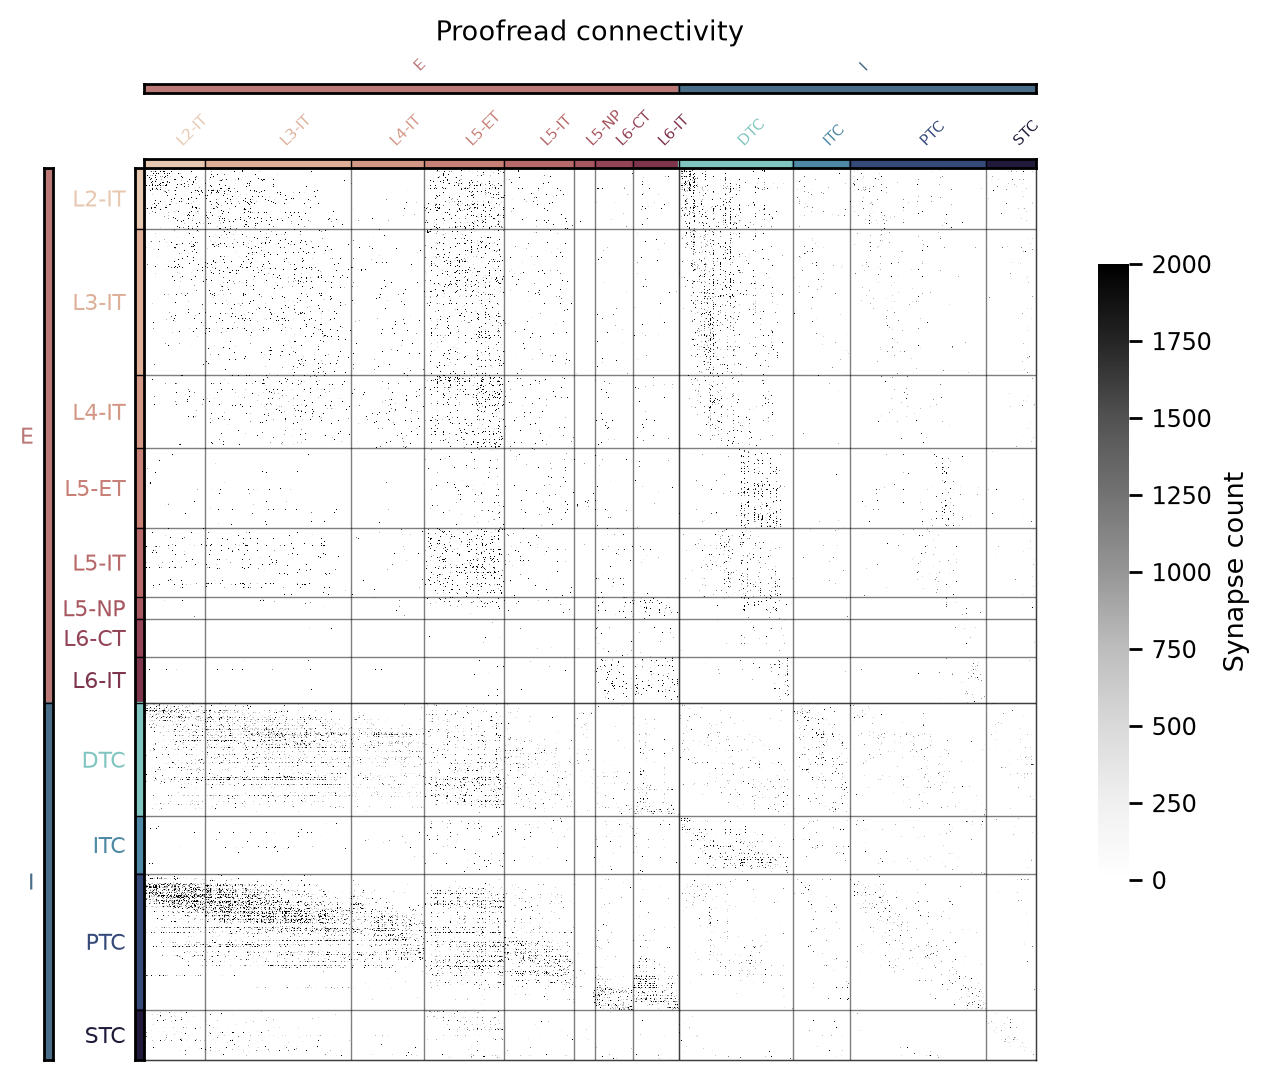

In [28]:
## Plot just synapses onto spine

fig, ax = plt.subplots(figsize=(8, 8), dpi=200)

category = 'spine' # This is synapses onto spines

category_syns_df = proof_proof_syn_table.query(f"target_structure == '{category}'")
category_syn_mat = make_adjacency(
    category_syns_df, source_cell_index=proof_cell_df, aggfunc="sum"
)
# render the adjacency plot
adjacencyplot(
    category_syn_mat,  # data values for the points
    nodes=proof_cell_df,  # data to organize the x and y axis
    groupby=["cell_type_coarse", "cell_type"],  # categorical variables to organize by
    sortby="pt_position_y",  # sort within groups by variable
    node_palette=cell_type_palette,
    title="Proofread connectivity",
    edge_palette="Greys",
    hue_norm=(0, 2000),  # normalize the color scale for the edges
    ax=ax,
    label_fontsize="xx-small",
    title_fontsize="medium",
    arc_labels=False
)


<div style="background: #DFF0D8; border-radius: 3px; padding: 10px;">
<p><b>Task 6:</b> Reproduce the plot above from 'spine' for 'shaft' and 'soma'

<b>Discussion:</b> For each of the common cell-type connectivity assumptions above, which hold up in the data? 

Find one thing that does not match your expectation, and write it on the whiteboard.
</div>

MOVE THIS TO AN EXERCISE